# Proyek Komputer: Indonesia Online Gambling Money Mule Accounts 2026
- **Nama:** Alif Setyo Wisnuaji
- **Email:** alifsetyowisnuaji@students.undip.ac.id, alifwisnuaji8@gmail.com
- **Prodi:** Matematika - S1
- **Fakultas:** Fakultas Sains dan Matematika
- **Universitas:** Universitas Diponegoro

Dataset: [Indonesia Online Gambling Bank Accounts Forensics](https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-online-gambling-bank-accounts-forensics) — 10.000 rekening bank/e-wallet Indonesia dengan 26 fitur forensik AML.

> **Catatan:** Dataset ini merupakan **data sintetis (benchmark riset)** yang dikalibrasi terhadap tipologi forensik publik (PPATK, BI, OJK), bukan data transaksi perbankan riil. Hasil analisis merupakan latihan/benchmark metodologi, bukan temuan empiris tentang kondisi perbankan Indonesia yang sebenarnya.

## Menentukan Pertanyaan Bisnis

Pertanyaan bisnis dirumuskan menggunakan framework **SMART**:

* **Specific** — jelas dan fokus pada topik tertentu, tidak bermakna ganda.
* **Measurable** — dapat dijawab dengan angka/metrik konkret dari dataset.
* **Action-Oriented** — hasilnya memberi arahan tindakan nyata bagi stakeholder.
* **Relevant** — sejalan dengan tujuan mitigasi risiko judi online dan AML.
* **Time-bound** — memiliki konteks waktu yang jelas (data forensik periode pengamatan 2026).

- **Pertanyaan 1:** Pada rekening yang terindikasi judi online (money mule), kombinasi `primary_transaction_channel` dan `kyc_verification_status` mana yang memiliki rata-rata `late_night_transaction_ratio` dan `passthrough_velocity_pct` tertinggi, serta berapa jumlah rekening pada kombinasi tersebut, sehingga tim Fraud & Risk Engine dapat memprioritaskan aturan pemblokiran otomatis (*automated freeze rule*) pada kombinasi kanal dan status KYC yang paling berisiko?
- **Pertanyaan 2:** Jenis institusi keuangan (`institution_type`) mana yang memiliki jumlah dan proporsi rekening terindikasi judi online tertinggi serta rata-rata `aml_composite_risk_score` tertinggi, sehingga tim kepatuhan dapat memprioritaskan audit dan pemantauan tambahan pada institusi tersebut?
- **Pertanyaan 3:** Indikator anomali utama (`primary_anomaly_indicator`) apa yang paling dominan pada rekening terindikasi judi online, dan bagaimana kaitannya dengan klasifikasi risiko akun, sehingga tim deteksi dapat memprioritaskan pembangunan aturan deteksi (*detection rule*) berdasarkan pola anomali tersebut?

### Penjelasan SMART Pertanyaan 1

***"Pada rekening yang terindikasi judi online (money mule), kombinasi `primary_transaction_channel` dan `kyc_verification_status` mana yang memiliki rata-rata `late_night_transaction_ratio` dan `passthrough_velocity_pct` tertinggi, serta berapa jumlah rekening pada kombinasi tersebut, sehingga tim Fraud & Risk Engine dapat memprioritaskan aturan pemblokiran otomatis (automated freeze rule) pada kombinasi kanal dan status KYC yang paling berisiko?"***

- **Specific**: fokus pada kombinasi kanal transaksi utama dan status verifikasi KYC pada subset rekening terindikasi judi online.
- **Measurable**: diukur dengan rata-rata `late_night_transaction_ratio` dan `passthrough_velocity_pct` per kombinasi, dilengkapi jumlah rekening (`n_accounts`) agar kombinasi bersampel kecil tidak disalahartikan.
- **Action-Oriented**: hasilnya menjadi dasar prioritas pembangunan *automated freeze rule* bagi tim Risk Engine.
- **Relevant**: berkaitan langsung dengan mitigasi celah teknis yang dimanfaatkan sindikat penampung judi online.
- **Time-bound**: menggunakan konteks data forensik periode pengamatan tahun 2026.

### Penjelasan SMART Pertanyaan 2

***"Jenis institusi keuangan (`institution_type`) mana yang memiliki jumlah dan proporsi rekening terindikasi judi online tertinggi serta rata-rata `aml_composite_risk_score` tertinggi, sehingga tim kepatuhan dapat memprioritaskan audit dan pemantauan tambahan pada institusi tersebut?"***

- **Specific**: membandingkan empat jenis institusi (bank BUMN, bank swasta tier-1, neo-bank digital, penyedia e-wallet).
- **Measurable**: diukur dengan jumlah rekening berisiko, proporsinya terhadap total rekening institusi tersebut, dan rata-rata skor risiko AML.
- **Action-Oriented**: menjadi dasar prioritas audit dan alokasi sumber daya pemantauan kepatuhan.
- **Relevant**: membantu institusi dengan eksposur risiko tertinggi memperkuat kontrol AML.
- **Time-bound**: berdasarkan data periode pengamatan tahun 2026.

### Penjelasan SMART Pertanyaan 3

***"Indikator anomali utama (`primary_anomaly_indicator`) apa yang paling dominan pada rekening terindikasi judi online, dan bagaimana kaitannya dengan klasifikasi risiko akun, sehingga tim deteksi dapat memprioritaskan pembangunan aturan deteksi (detection rule) berdasarkan pola anomali tersebut?"***

- **Specific**: fokus pada distribusi lima indikator anomali pada subset rekening terindikasi judi online dan kaitannya dengan `account_risk_classification`.
- **Measurable**: diukur dengan jumlah dan proporsi rekening per indikator anomali, serta rata-rata metrik risiko pendukung.
- **Action-Oriented**: menjadi dasar prioritas pembangunan *detection rule* pada pola anomali yang paling umum.
- **Relevant**: deteksi dini pola anomali dominan adalah inti operasional sistem anti-judi online/AML.
- **Time-bound**: berdasarkan data periode pengamatan tahun 2026.

## Import Semua Packages/Library yang Digunakan

In [1]:
# Library untuk manipulasi dan pengolahan data
import pandas as pd
import numpy as np

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk mengunduh dataset dari Kaggle
import kagglehub

# Pengaturan gaya dan estetika grafik
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Menginstal Streamlit dan menyiapkan folder dashboard
!pip install streamlit -q
import streamlit as st

# Library pendukung sistem file
import os
os.makedirs('dashboard', exist_ok=True)

# Library pendukung proses tunnel dashboard (dieksekusi pada bagian Dashboard)
import subprocess, time, urllib.request

## Data Wrangling

### Gathering Data

#### Load df utama dari dataset Kaggle

In [2]:
# Quickstart: Ingest this research benchmark in 1 line via kagglehub
path = kagglehub.dataset_download("luthfimuthathohirin/indonesia-online-gambling-bank-accounts-forensics")
print("Path to benchmark dataset:", path)

100%|██████████| 1.10M/1.10M [00:00<00:00, 30.6MB/s]

Extracting files...
Path to benchmark dataset: /root/.cache/kagglehub/datasets/luthfimuthathohirin/indonesia-online-gambling-bank-accounts-forensics/versions/2


In [3]:
# 1. Mencari lokasi file CSV hasil unduhan
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
assert len(csv_files) == 1, f"Ditemukan {len(csv_files)} file CSV, perlu dipilih salah satu: {csv_files}"
csv_path = os.path.join(path, csv_files[0])
print("File dataset:", csv_files[0])

# 2. Loading dataset ke dalam DataFrame pandas (df)
df = pd.read_csv(csv_path)

# 3. Menampilkan 5 baris pertama DataFrame
df.head()

File dataset: indonesia_online_gambling_mule_accounts_enriched_2026.csv


,account_id,institution_type,account_holder_age,account_dormancy_days,daily_inflow_volume_count,total_daily_inflow_amount_idr,daily_outflow_volume_count,total_daily_outflow_amount_idr,average_transaction_size_idr,primary_transaction_channel,...,micro_deposit_frequency_ratio,average_holding_duration_hours,device_churn_rate,burst_transaction_velocity_per_min,dormancy_reactivation_friction_score,aml_composite_risk_score,account_risk_classification,primary_anomaly_indicator,cot_aml_forensic_rationale,confidence_score
0,ACC_MULE_020C471398,Digital Neo-Bank,27,361,491,25000000,358,24200000,58000,Fast Real-Time Bank Transfer / BI-FAST,...,1.37,0.12,1.100,3.68,9.25,66.2,Dormant-Takeover-Syndicate,VPN-Proxy-Multi-Device-Churn,Rekening 'ACC_MULE_020C471398' pada 'Digital N...,0.987
1,ACC_MULE_045C191F9C,Digital Neo-Bank,25,442,1533,49890000,61,49290000,62200,Fast Real-Time Bank Transfer / BI-FAST,...,25.13,0.75,0.967,11.50,9.62,88.8,Dormant-Takeover-Syndicate,VPN-Proxy-Multi-Device-Churn,Rekening 'ACC_MULE_045C191F9C' pada 'Digital N...,0.984
2,ACC_MULE_06565A3367,Digital Neo-Bank,61,524,1805,130240000,334,128390000,120900,Fast Real-Time Bank Transfer / BI-FAST,...,5.40,0.33,1.133,13.54,10.00,74.0,Dormant-Takeover-Syndicate,VPN-Proxy-Multi-Device-Churn,Rekening 'ACC_MULE_06565A3367' pada 'Digital N...,0.987
3,ACC_MULE_0862F0FD0A,Digital Neo-Bank,23,204,653,45400000,32,43230000,129400,Fast Real-Time Bank Transfer / BI-FAST,...,20.41,0.23,0.433,4.90,7.40,77.5,Layering-Mule-Account,Dormant-Sudden-High-Volume,Rekening 'ACC_MULE_0862F0FD0A' pada 'Digital N...,0.916
4,ACC_MULE_0906062AE5,Digital Neo-Bank,28,424,1324,148580000,140,145020000,200500,Fast Real-Time Bank Transfer / BI-FAST,...,9.46,0.05,0.933,9.93,10.00,75.8,Dormant-Takeover-Syndicate,VPN-Proxy-Multi-Device-Churn,Rekening 'ACC_MULE_0906062AE5' pada 'Digital N...,0.981


**Insight:**
- DataFrame utama berhasil dimuat: **10.000 baris x 26 kolom**. Setiap baris merepresentasikan **satu rekening** (bukan satu transaksi), dilengkapi fitur perilaku transaksi, kanal, KYC, skor risiko, dan klasifikasi forensik.
- Dataset mencakup lima klasifikasi akun: tiga kategori money mule yang berkaitan dengan ekosistem judi online (`Dormant-Takeover-Syndicate`, `Direct-Gambling-Collector-Mule`, `Layering-Mule-Account`), serta `Merchant-Commercial-Account` dan `Legitimate-Personal-Account` sebagai akun komersial/pembanding.
- Data siap memasuki tahap Assessing Data.

### Assessing Data

#### Identifying df problem (missing values, duplikasi, tipe data, konsistensi kategori)

In [4]:
# 1. Memeriksa informasi umum & tipe data
print("-------- INFORMASI DATASET --------")
df.info()

# 2. Memeriksa missing values (nilai hilang)
print("\nJumlah Missing Value per Kolom:")
print(df.isnull().sum())

# 3. Memeriksa duplikasi baris & duplikasi primary key (account_id)
print("\nJumlah Duplikasi Data:")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")
print(f"Jumlah account_id duplikat: {df['account_id'].duplicated().sum()}")

# 4. Ringkasan statistik deskriptif variabel numerik (pengecekan rentang nilai/outlier)
print("\nStatistik Deskriptif df:")
df.describe()

-------- INFORMASI DATASET --------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 26 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   account_id                            10000 non-null  object 
 1   institution_type                      10000 non-null  object 
 2   account_holder_age                    10000 non-null  int64  
 3   account_dormancy_days                 10000 non-null  int64  
 4   daily_inflow_volume_count             10000 non-null  int64  
 5   total_daily_inflow_amount_idr         10000 non-null  int64  
 6   daily_outflow_volume_count            10000 non-null  int64  
 7   total_daily_outflow_amount_idr        10000 non-null  int64  
 8   average_transaction_size_idr          10000 non-null  int64  
 9   primary_transaction_channel           10000 non-null  object 
 10  late_night_transaction_ratio          10000 non

,account_holder_age,account_dormancy_days,daily_inflow_volume_count,total_daily_inflow_amount_idr,daily_outflow_volume_count,total_daily_outflow_amount_idr,average_transaction_size_idr,late_night_transaction_ratio,device_fingerprint_change_count,inflow_outflow_ratio,passthrough_velocity_pct,micro_deposit_frequency_ratio,average_holding_duration_hours,device_churn_rate,burst_transaction_velocity_per_min,dormancy_reactivation_friction_score,aml_composite_risk_score,confidence_score
count,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.000000,1.000000e+04,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,34.452400,109.520100,222.231700,2.524560e+07,50.998900,2.271296e+07,1.142353e+06,20.552847,5.899900,1.449809,75.837750,3.302974,66.601729,0.196631,1.667737,2.191106,31.601060,0.953585
std,12.104875,236.546182,469.398181,4.042345e+07,101.675069,4.002419e+07,1.085319e+06,24.501057,8.613762,0.498554,20.949614,12.597596,73.407996,0.287145,3.520169,3.665958,21.085847,0.018117
min,17.000000,0.000000,1.000000,2.580000e+05,1.000000,1.980000e+05,3.490000e+04,0.000000,1.000000,0.952400,35.000000,0.080000,0.050000,0.033000,0.010000,0.000000,9.300000,0.908000
25%,25.000000,4.000000,4.000000,5.439500e+06,5.000000,3.523750e+06,2.740250e+05,4.367500,1.000000,1.036575,57.657500,0.670000,14.800000,0.033000,0.030000,0.000000,17.500000,0.938000
50%,33.000000,12.000000,6.000000,9.579500e+06,7.000000,6.469500e+06,8.873500e+05,10.000000,2.000000,1.258100,79.490000,1.000000,44.810000,0.067000,0.050000,0.000000,23.300000,0.952000
75%,42.000000,38.000000,9.000000,2.033350e+07,10.000000,1.550725e+07,1.606725e+06,18.000000,4.000000,1.734275,96.472500,1.920000,95.910000,0.133000,0.070000,4.210000,32.600000,0.968000
max,68.000000,1180.000000,1849.000000,2.719300e+08,419.000000,2.632700e+08,1.157870e+07,94.800000,34.000000,2.857100,100.000000,311.600000,695.690000,1.133000,13.870000,10.000000,98.400000,0.990000


In [5]:
# 5. Memeriksa nilai dan frekuensi setiap kolom kategorikal/boolean
categorical_cols_check = df.select_dtypes(include=['object', 'bool']).columns

for col in categorical_cols_check:
    # Abaikan kolom ID dan teks panjang rationale
    if col not in ['account_id', 'cot_aml_forensic_rationale']:
        print(f"--- Distribusi kolom '{col}': ---")
        print(df[col].value_counts(dropna=False))
        print("-" * 50)

--- Distribusi kolom 'institution_type': ---
institution_type
State-Owned Commercial Bank / BUMN    3258
Private Tier-1 Bank                   2782
Digital Neo-Bank                      2089
Major E-Wallet Provider               1871
Name: count, dtype: int64
--------------------------------------------------
--- Distribusi kolom 'primary_transaction_channel': ---
primary_transaction_channel
QRIS Dynamic Merchant                     3369
Fast Real-Time Bank Transfer / BI-FAST    3317
Virtual Account / VA                      2630
Payment Gateway Aggregator                 684
Name: count, dtype: int64
--------------------------------------------------
--- Distribusi kolom 'proxy_vpn_detection_flag': ---
proxy_vpn_detection_flag
False    7864
True     2136
Name: count, dtype: int64
--------------------------------------------------
--- Distribusi kolom 'kyc_verification_status': ---
kyc_verification_status
Fully Verified Biometric                     5667
Basic KTP Scan                 

**Steps to Take:**

Hasil assessing menunjukkan data sudah bersih (0 missing values, 0 duplikat, tipe data sesuai, kategori konsisten), sehingga **tidak diperlukan imputasi maupun penghapusan baris**. Langkah persiapan yang dilakukan pada tahap Cleaning:
1. **Konversi tipe kategorikal**: mengubah kolom `object` menjadi `category` untuk efisiensi memori dan kerapian agregasi.
2. **Membuat subset rekening berisiko tinggi (`high_risk_df`)**: memfilter `account_risk_classification` pada tiga kategori money mule yang berkaitan langsung dengan ekosistem judi online. Kategori `Merchant-Commercial-Account` dan `Legitimate-Personal-Account` tidak diikutkan karena berperan sebagai akun komersial/pembanding.
3. **Agregasi dan eksplorasi** untuk menjawab ketiga pertanyaan bisnis dilakukan pada tahap EDA.

**Insight:**
- **Tidak ada missing values**: seluruh 10.000 observasi pada 26 kolom terisi lengkap.
- **Tidak ada duplikasi**: tidak ada baris duplikat dan seluruh `account_id` unik (10.000 rekening independen).
- **Tipe data sudah sesuai**: numerik (`int64`/`float64`), kategorikal (`object`), dan boolean (`bool`).
- **Kategori konsisten**: setiap kolom kategorikal hanya memuat nilai yang terdefinisi (4 institusi, 4 kanal, 4 status KYC, 5 klasifikasi risiko, 5 indikator anomali).
- **Implikasi**: seluruh sampel dapat digunakan; fokus cleaning adalah konversi tipe dan pembuatan subset analisis.

### Cleaning Data

#### Konversi tipe kategorikal dan filtering rekening terindikasi judi online

In [6]:
# 1. Membuat salinan DataFrame utama untuk proses pembersihan
df_cleaned = df.copy()

# 2. Mengubah kolom kategorikal 'object' menjadi 'category'
categorical_cols = [
    'institution_type',
    'primary_transaction_channel',
    'kyc_verification_status',
    'account_risk_classification',
    'primary_anomaly_indicator'
]
for col in categorical_cols:
    df_cleaned[col] = df_cleaned[col].astype('category')

# 3. Memfilter rekening yang terindikasi judi online (money mule)
kategori_judi_online = [
    'Dormant-Takeover-Syndicate',
    'Direct-Gambling-Collector-Mule',
    'Layering-Mule-Account'
]
high_risk_df = df_cleaned[df_cleaned['account_risk_classification'].isin(kategori_judi_online)].copy()

# 4. Menghapus kategori yang tidak terpakai pada hasil filter
for col in categorical_cols:
    high_risk_df[col] = high_risk_df[col].cat.remove_unused_categories()

# 5. Verifikasi hasil cleaning
print("=== TIPE DATA SETELAH CLEANING ===")
print(df_cleaned[categorical_cols].dtypes)
print("\n=== DISTRIBUSI KATEGORI PADA high_risk_df ===")
print(high_risk_df['account_risk_classification'].value_counts())
print(f"\nTotal rekening terindikasi judi online: {len(high_risk_df)} dari {len(df_cleaned)} rekening ({len(high_risk_df)/len(df_cleaned)*100:.1f}%)")

=== TIPE DATA SETELAH CLEANING ===
institution_type               category
primary_transaction_channel    category
kyc_verification_status        category
account_risk_classification    category
primary_anomaly_indicator      category
dtype: object

=== DISTRIBUSI KATEGORI PADA high_risk_df ===
account_risk_classification
Dormant-Takeover-Syndicate        1408
Direct-Gambling-Collector-Mule     414
Layering-Mule-Account              378
Name: count, dtype: int64

Total rekening terindikasi judi online: 2200 dari 10000 rekening (22.0%)


**Insight:**
- Subset `high_risk_df` berisi **2.200 rekening (22,0% dari total)**: `Dormant-Takeover-Syndicate` (1.408), `Direct-Gambling-Collector-Mule` (414), dan `Layering-Mule-Account` (378).
- Seluruh kolom kategorikal telah bertipe `category` dengan kategori yang relevan saja; data siap untuk agregasi EDA.

## Exploratory Data Analysis (EDA)

### Explore kombinasi kanal x KYC (Pertanyaan 1)

In [7]:
# Agregasi rata-rata indikator anomali per kombinasi kanal x KYC
channel_kyc_agg = (
    high_risk_df
    .groupby(['primary_transaction_channel', 'kyc_verification_status'], observed=True)
    .agg(
        n_accounts=('account_id', 'count'),
        avg_late_night_pct=('late_night_transaction_ratio', 'mean'),
        avg_passthrough_pct=('passthrough_velocity_pct', 'mean')
    )
    .reset_index()
)

print("=== Kombinasi Kanal x KYC (urut rata-rata passthrough velocity tertinggi) ===")
channel_kyc_agg.sort_values('avg_passthrough_pct', ascending=False).round(3)

=== Kombinasi Kanal x KYC (urut rata-rata passthrough velocity tertinggi) ===


,primary_transaction_channel,kyc_verification_status,n_accounts,avg_late_night_pct,avg_passthrough_pct
9,Virtual Account / VA,Basic KTP Scan,67,64.212,97.619
6,QRIS Dynamic Merchant,Basic KTP Scan,94,62.549,97.551
2,Fast Real-Time Bank Transfer / BI-FAST,Third-Party Acquired / Rekening Jual-Beli,131,65.847,97.493
3,Payment Gateway Aggregator,Basic KTP Scan,35,64.640,97.460
8,QRIS Dynamic Merchant,Third-Party Acquired / Rekening Jual-Beli,554,63.137,97.416
10,Virtual Account / VA,Dormant Reactivated,203,64.383,97.413
7,QRIS Dynamic Merchant,Dormant Reactivated,318,64.305,97.408
4,Payment Gateway Aggregator,Dormant Reactivated,88,63.543,97.395
5,Payment Gateway Aggregator,Third-Party Acquired / Rekening Jual-Beli,172,64.948,97.388
1,Fast Real-Time Bank Transfer / BI-FAST,Dormant Reactivated,101,64.596,97.378


In [8]:
# Kombinasi dengan rata-rata late-night transaction ratio tertinggi
print("=== Kombinasi Kanal x KYC (urut rata-rata late night tertinggi) ===")
channel_kyc_agg.sort_values('avg_late_night_pct', ascending=False).round(3)

=== Kombinasi Kanal x KYC (urut rata-rata late night tertinggi) ===


,primary_transaction_channel,kyc_verification_status,n_accounts,avg_late_night_pct,avg_passthrough_pct
2,Fast Real-Time Bank Transfer / BI-FAST,Third-Party Acquired / Rekening Jual-Beli,131,65.847,97.493
0,Fast Real-Time Bank Transfer / BI-FAST,Basic KTP Scan,29,65.214,97.271
5,Payment Gateway Aggregator,Third-Party Acquired / Rekening Jual-Beli,172,64.948,97.388
3,Payment Gateway Aggregator,Basic KTP Scan,35,64.640,97.460
1,Fast Real-Time Bank Transfer / BI-FAST,Dormant Reactivated,101,64.596,97.378
10,Virtual Account / VA,Dormant Reactivated,203,64.383,97.413
7,QRIS Dynamic Merchant,Dormant Reactivated,318,64.305,97.408
9,Virtual Account / VA,Basic KTP Scan,67,64.212,97.619
11,Virtual Account / VA,Third-Party Acquired / Rekening Jual-Beli,408,63.777,97.347
4,Payment Gateway Aggregator,Dormant Reactivated,88,63.543,97.395


In [9]:
# Kombinasi dengan jumlah rekening terbesar (konteks skala operasional)
print("=== Kombinasi Kanal x KYC (urut jumlah rekening terbesar) ===")
channel_kyc_agg.sort_values('n_accounts', ascending=False).round(3)

=== Kombinasi Kanal x KYC (urut jumlah rekening terbesar) ===


,primary_transaction_channel,kyc_verification_status,n_accounts,avg_late_night_pct,avg_passthrough_pct
8,QRIS Dynamic Merchant,Third-Party Acquired / Rekening Jual-Beli,554,63.137,97.416
11,Virtual Account / VA,Third-Party Acquired / Rekening Jual-Beli,408,63.777,97.347
7,QRIS Dynamic Merchant,Dormant Reactivated,318,64.305,97.408
10,Virtual Account / VA,Dormant Reactivated,203,64.383,97.413
5,Payment Gateway Aggregator,Third-Party Acquired / Rekening Jual-Beli,172,64.948,97.388
2,Fast Real-Time Bank Transfer / BI-FAST,Third-Party Acquired / Rekening Jual-Beli,131,65.847,97.493
1,Fast Real-Time Bank Transfer / BI-FAST,Dormant Reactivated,101,64.596,97.378
6,QRIS Dynamic Merchant,Basic KTP Scan,94,62.549,97.551
4,Payment Gateway Aggregator,Dormant Reactivated,88,63.543,97.395
9,Virtual Account / VA,Basic KTP Scan,67,64.212,97.619


**Insight:**
- `passthrough_velocity_pct` sangat seragam dan tinggi di semua kombinasi (97,27%–97,62%) — hampir seluruh dana masuk langsung keluar pada hari yang sama. Indikator ini menegaskan pola mule, tetapi tidak cukup membedakan prioritas antar kombinasi.
- Rata-rata `late_night_transaction_ratio` (berskala persen) lebih bervariasi; tertinggi pada kanal **BI-FAST dengan KYC lemah** (rekening jual-beli: 65,85%; Basic KTP Scan: 65,21%).
- Kombinasi dengan volume terbesar: **QRIS Dynamic Merchant x Third-Party Acquired / Rekening Jual-Beli (554 rekening)**.

### Explore jenis institusi keuangan (Pertanyaan 2)

In [10]:
# Jumlah rekening berisiko, proporsi, dan rata-rata skor AML per jenis institusi
institution_analysis = (
    df_cleaned.groupby('institution_type', observed=True)
    .agg(total_accounts=('account_id', 'count'))
    .join(
        high_risk_df.groupby('institution_type', observed=True)
        .agg(
            high_risk_accounts=('account_id', 'count'),
            avg_aml_risk_score=('aml_composite_risk_score', 'mean')
        )
    )
    .fillna(0)
)
institution_analysis['high_risk_pct'] = (
    institution_analysis['high_risk_accounts'] / institution_analysis['total_accounts'] * 100
)
institution_analysis = institution_analysis.sort_values('high_risk_pct', ascending=False)

print("=== Analisis Risiko per Jenis Institusi ===")
institution_analysis.round(2)

=== Analisis Risiko per Jenis Institusi ===


,total_accounts,high_risk_accounts,avg_aml_risk_score,high_risk_pct
institution_type,,,,
Digital Neo-Bank,2089,702,68.81,33.60
Major E-Wallet Provider,1871,620,69.03,33.14
State-Owned Commercial Bank / BUMN,3258,507,68.76,15.56
Private Tier-1 Bank,2782,371,69.55,13.34


**Insight:**
- **Digital Neo-Bank** memiliki jumlah rekening berisiko terbanyak (702) sekaligus proporsi tertinggi (33,60%), disusul **Major E-Wallet Provider** (620; 33,14%).
- Bank BUMN (15,56%) dan Private Tier-1 Bank (13,34%) memiliki proporsi jauh lebih rendah.
- Rata-rata skor AML rekening berisiko relatif setara antar institusi (68,76–69,55); pembeda utama adalah jumlah dan proporsi, bukan skor rata-rata.

### Explore indikator anomali utama (Pertanyaan 3)

In [11]:
# Distribusi indikator anomali pada rekening terindikasi judi online
anomaly_analysis = (
    high_risk_df
    .groupby('primary_anomaly_indicator', observed=True)
    .agg(
        n_accounts=('account_id', 'count'),
        avg_late_night_pct=('late_night_transaction_ratio', 'mean'),
        avg_passthrough_pct=('passthrough_velocity_pct', 'mean'),
        avg_aml_risk_score=('aml_composite_risk_score', 'mean')
    )
    .sort_values('n_accounts', ascending=False)
)
anomaly_analysis['share_pct'] = anomaly_analysis['n_accounts'] / len(high_risk_df) * 100

print("=== Distribusi Indikator Anomali pada Rekening Terindikasi Judi Online ===")
anomaly_analysis.round(2)

=== Distribusi Indikator Anomali pada Rekening Terindikasi Judi Online ===


,n_accounts,avg_late_night_pct,avg_passthrough_pct,avg_aml_risk_score,share_pct
primary_anomaly_indicator,,,,,
Dormant-Sudden-High-Volume,1269,64.09,97.47,67.68,57.68
VPN-Proxy-Multi-Device-Churn,827,63.53,97.34,71.51,37.59
Late-Night-Burst-Clustering,42,77.71,97.56,65.82,1.91
Rapid-Passthrough-Zero-Balance,33,58.84,97.07,62.53,1.50
High-Frequency-Micro-Deposit,29,58.03,97.42,66.11,1.32


In [12]:
# Kaitan indikator anomali dengan klasifikasi risiko akun
anomaly_classification = pd.crosstab(
    high_risk_df['primary_anomaly_indicator'],
    high_risk_df['account_risk_classification']
)

print("=== Crosstab Indikator Anomali x Klasifikasi Risiko ===")
anomaly_classification

=== Crosstab Indikator Anomali x Klasifikasi Risiko ===


account_risk_classification,Direct-Gambling-Collector-Mule,Dormant-Takeover-Syndicate,Layering-Mule-Account
primary_anomaly_indicator,,,
Dormant-Sudden-High-Volume,382,540,347
High-Frequency-Micro-Deposit,13,9,7
Late-Night-Burst-Clustering,14,17,11
Rapid-Passthrough-Zero-Balance,5,15,13
VPN-Proxy-Multi-Device-Churn,0,827,0


**Insight:**
- Dua indikator mendominasi: **Dormant-Sudden-High-Volume (1.269 rekening; 57,68%)** dan **VPN-Proxy-Multi-Device-Churn (827 rekening; 37,59%)** — bersama-sama mencakup ~95% rekening berisiko.
- Pola sangat terkait klasifikasi: **seluruh 827 kasus VPN-Proxy-Multi-Device-Churn berasal dari `Dormant-Takeover-Syndicate`**, sedangkan Dormant-Sudden-High-Volume tersebar merata di ketiga klasifikasi mule.
- Tiga indikator lain (Late-Night-Burst-Clustering, Rapid-Passthrough-Zero-Balance, High-Frequency-Micro-Deposit) masing-masing hanya ~1–2% sebagai indikator *utama*, meskipun perilakunya tetap melekat pada hampir semua rekening mule (lihat keseragaman passthrough di EDA Pertanyaan 1).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kombinasi kanal x KYC paling berisiko

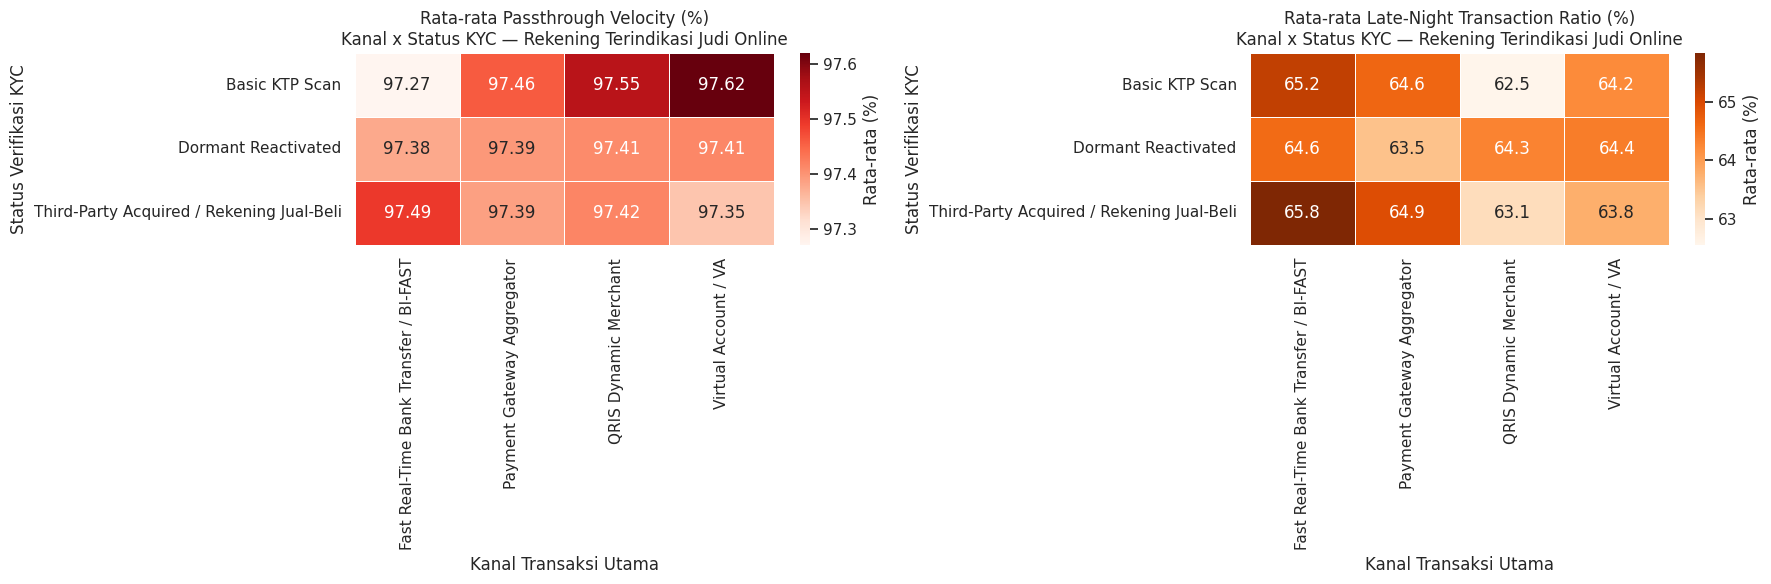

In [13]:
# Heatmap rata-rata passthrough velocity dan late-night ratio per kombinasi kanal x KYC
pivot_passthrough = channel_kyc_agg.pivot(
    index='kyc_verification_status',
    columns='primary_transaction_channel',
    values='avg_passthrough_pct'
)
pivot_late_night = channel_kyc_agg.pivot(
    index='kyc_verification_status',
    columns='primary_transaction_channel',
    values='avg_late_night_pct'
)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(pivot_passthrough, annot=True, fmt='.2f', cmap='Reds',
            linewidths=0.5, ax=axes[0], cbar_kws={'label': 'Rata-rata (%)'})
axes[0].set_title('Rata-rata Passthrough Velocity (%)\nKanal x Status KYC — Rekening Terindikasi Judi Online', fontsize=12)
axes[0].set_xlabel('Kanal Transaksi Utama')
axes[0].set_ylabel('Status Verifikasi KYC')

sns.heatmap(pivot_late_night, annot=True, fmt='.1f', cmap='Oranges',
            linewidths=0.5, ax=axes[1], cbar_kws={'label': 'Rata-rata (%)'})
axes[1].set_title('Rata-rata Late-Night Transaction Ratio (%)\nKanal x Status KYC — Rekening Terindikasi Judi Online', fontsize=12)
axes[1].set_xlabel('Kanal Transaksi Utama')
axes[1].set_ylabel('Status Verifikasi KYC')

plt.tight_layout()
plt.show()

**Insight:**
- Hampir semua sel berwarna merah pekat pada heatmap passthrough (97%+) — perbedaan antar kombinasi sangat kecil, sehingga prioritas tidak bisa ditentukan dari indikator ini saja.
- Heatmap late-night menunjukkan kanal **BI-FAST** konsisten paling tinggi, terutama pada KYC `Third-Party Acquired / Rekening Jual-Beli` dan `Basic KTP Scan`.

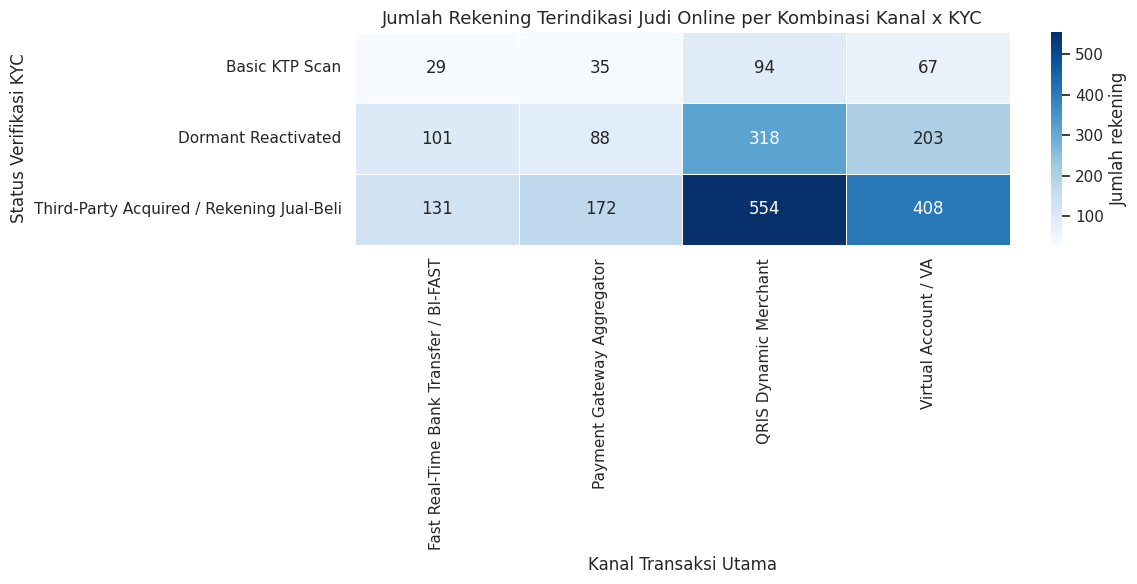

In [14]:
# Heatmap jumlah rekening per kombinasi kanal x KYC (konteks ukuran sampel)
pivot_count = channel_kyc_agg.pivot(
    index='kyc_verification_status',
    columns='primary_transaction_channel',
    values='n_accounts'
)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_count, annot=True, fmt='d', cmap='Blues', linewidths=0.5,
            cbar_kws={'label': 'Jumlah rekening'})
plt.title('Jumlah Rekening Terindikasi Judi Online per Kombinasi Kanal x KYC', fontsize=13)
plt.xlabel('Kanal Transaksi Utama')
plt.ylabel('Status Verifikasi KYC')
plt.tight_layout()
plt.show()

**Insight:**
- Konsentrasi terbesar ada pada **QRIS x Rekening Jual-Beli (554)** dan **VA x Rekening Jual-Beli (408)** — status KYC `Third-Party Acquired` mendominasi di hampir semua kanal.
- Sel dengan rata-rata tinggi tetapi sampel kecil (mis. BI-FAST x Basic KTP Scan, 29 rekening) perlu dibaca hati-hati sebelum dijadikan dasar aturan otomatis.

### Pertanyaan 2: Institusi dengan eksposur risiko tertinggi

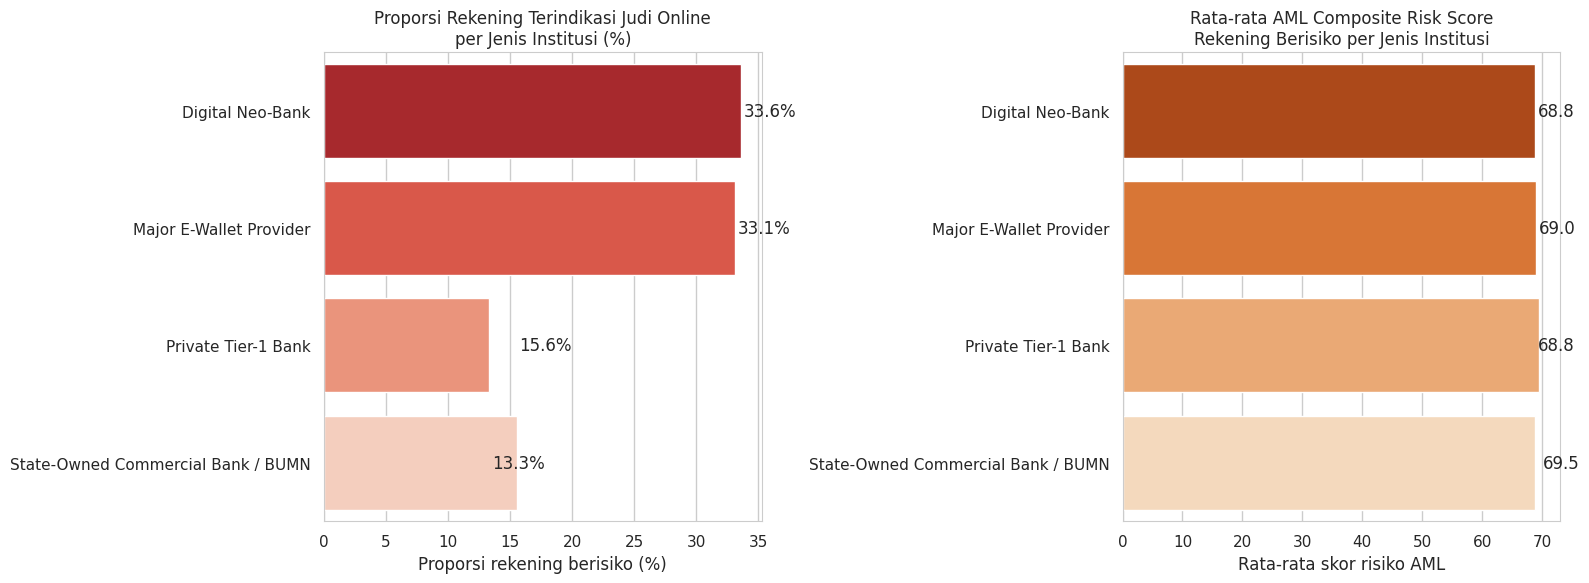

In [15]:
# Bar chart proporsi rekening berisiko dan rata-rata skor AML per institusi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=institution_analysis.reset_index(),
            x='high_risk_pct', y='institution_type', hue='institution_type',
            palette='Reds_r', legend=False, ax=axes[0])
axes[0].set_title('Proporsi Rekening Terindikasi Judi Online\nper Jenis Institusi (%)', fontsize=12)
axes[0].set_xlabel('Proporsi rekening berisiko (%)')
axes[0].set_ylabel('')
for i, v in enumerate(institution_analysis['high_risk_pct']):
    axes[0].text(v + 0.2, i, f'{v:.1f}%', va='center')

sns.barplot(data=institution_analysis.reset_index(),
            x='avg_aml_risk_score', y='institution_type', hue='institution_type',
            palette='Oranges_r', legend=False, ax=axes[1])
axes[1].set_title('Rata-rata AML Composite Risk Score\nRekening Berisiko per Jenis Institusi', fontsize=12)
axes[1].set_xlabel('Rata-rata skor risiko AML')
axes[1].set_ylabel('')
for i, v in enumerate(institution_analysis['avg_aml_risk_score']):
    axes[1].text(v + 0.5, i, f'{v:.1f}', va='center')

plt.tight_layout()
plt.show()

**Insight:**
- Neo-bank digital dan e-wallet menonjol: sekitar **sepertiga** rekeningnya dalam dataset terindikasi money mule, dua kali lipat proporsi bank konvensional.
- Skor AML rata-rata antar institusi hampir setara — menegaskan bahwa eksposur (jumlah/proporsi), bukan intensitas skor, yang membedakan institusi.

### Pertanyaan 3: Indikator anomali paling dominan

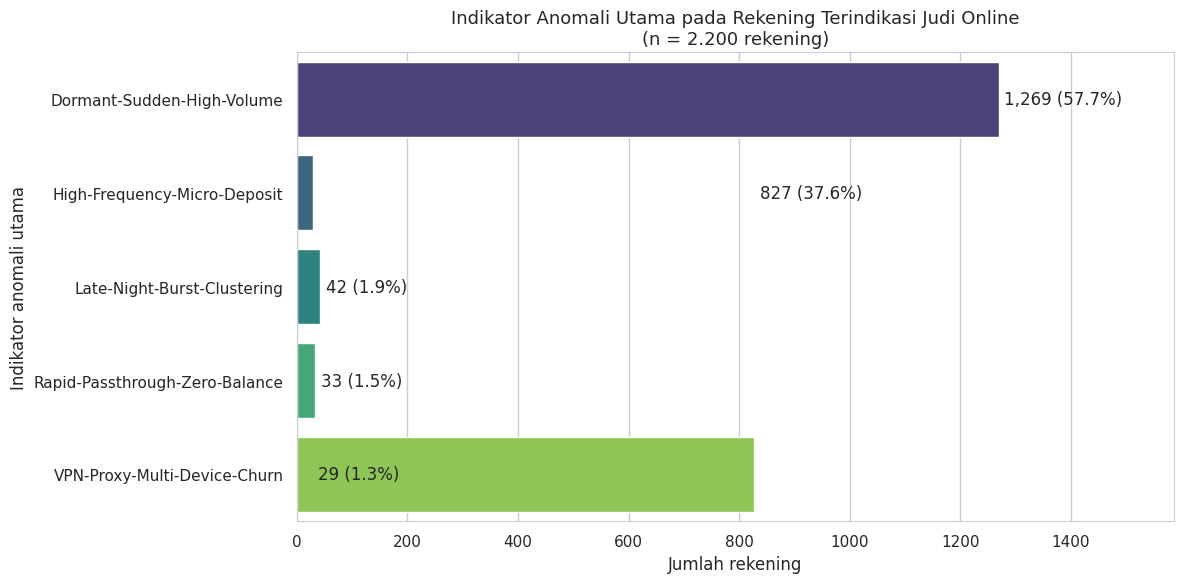

In [16]:
# Bar chart jumlah rekening per indikator anomali utama
anomaly_plot = anomaly_analysis.reset_index()

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=anomaly_plot,
                 x='n_accounts', y='primary_anomaly_indicator',
                 hue='primary_anomaly_indicator', palette='viridis', legend=False)
plt.title('Indikator Anomali Utama pada Rekening Terindikasi Judi Online\n(n = 2.200 rekening)', fontsize=13)
plt.xlabel('Jumlah rekening')
plt.ylabel('Indikator anomali utama')
for i, row in enumerate(anomaly_plot.itertuples()):
    ax.text(row.n_accounts + 10, i, f'{row.n_accounts:,} ({row.share_pct:.1f}%)', va='center')
plt.xlim(0, anomaly_plot['n_accounts'].max() * 1.25)
plt.tight_layout()
plt.show()

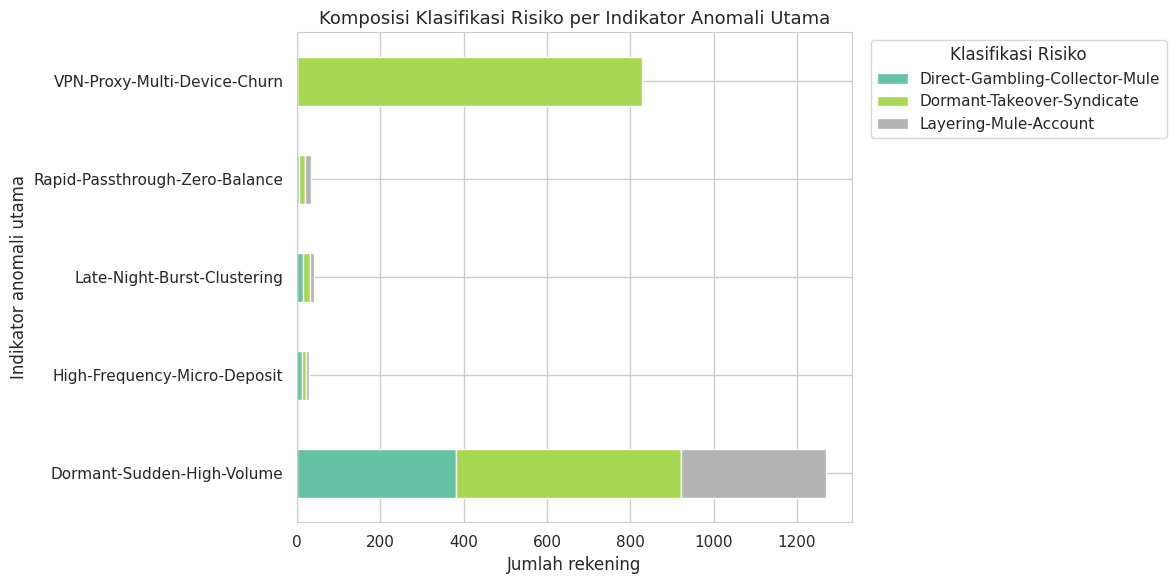

In [17]:
# Stacked bar: komposisi klasifikasi risiko per indikator anomali
anomaly_classification.plot(
    kind='barh', stacked=True, figsize=(12, 6),
    colormap='Set2', edgecolor='white'
)
plt.title('Komposisi Klasifikasi Risiko per Indikator Anomali Utama', fontsize=13)
plt.xlabel('Jumlah rekening')
plt.ylabel('Indikator anomali utama')
plt.legend(title='Klasifikasi Risiko', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Insight:**
- **Dormant-Sudden-High-Volume** adalah indikator utama paling dominan (57,7%), muncul merata di ketiga jenis klasifikasi mule — pola "rekening tidur tiba-tiba aktif dengan volume tinggi" adalah sinyal deteksi paling universal.
- **VPN-Proxy-Multi-Device-Churn** (37,6%) eksklusif pada `Dormant-Takeover-Syndicate` — sinyal khas pengambilalihan rekening dormant oleh sindikat.

## Analisis Lanjutan (Opsional)

### Clustering sederhana berbasis aturan: profil risiko VPN pada rekening dormant-takeover

Sebagai analisis lanjutan, dilakukan pengelompokan (*rule-based clustering*) rekening berisiko berdasarkan flag deteksi VPN/proxy untuk melihat apakah penggunaan VPN/proxy memperkuat profil risiko akun.

In [18]:
# Pengelompokan rekening berisiko berdasarkan flag VPN/proxy
vpn_cluster = (
    high_risk_df
    .groupby('proxy_vpn_detection_flag', observed=True)
    .agg(
        n_accounts=('account_id', 'count'),
        avg_late_night_pct=('late_night_transaction_ratio', 'mean'),
        avg_passthrough_pct=('passthrough_velocity_pct', 'mean'),
        avg_aml_risk_score=('aml_composite_risk_score', 'mean'),
        avg_device_churn=('device_fingerprint_change_count', 'mean')
    )
)
vpn_cluster['share_pct'] = vpn_cluster['n_accounts'] / len(high_risk_df) * 100
vpn_cluster.index = vpn_cluster.index.map({True: 'Terdeteksi VPN/Proxy', False: 'Tanpa VPN/Proxy'})

print("=== Profil Risiko per Kelompok VPN/Proxy ===")
vpn_cluster.round(2)

=== Profil Risiko per Kelompok VPN/Proxy ===


,n_accounts,avg_late_night_pct,avg_passthrough_pct,avg_aml_risk_score,avg_device_churn,share_pct
proxy_vpn_detection_flag,,,,,,
Tanpa VPN/Proxy,390,63.39,97.42,56.46,20.84,17.73
Terdeteksi VPN/Proxy,1810,64.11,97.41,71.68,20.32,82.27


**Insight:**
- **1.810 dari 2.200 rekening berisiko (82,3%) terdeteksi menggunakan VPN/proxy** — penggunaan VPN/proxy adalah penyerta yang sangat umum pada rekening mule.
- Kelompok dengan VPN/proxy memiliki rata-rata skor AML jauh lebih tinggi (71,68 vs 56,46), memperkuat sinyal bahwa flag VPN layak menjadi salah satu variabel utama dalam aturan deteksi/pembekuan.

## Dashboard (Streamlit)

Bagian ini membangun **dashboard interaktif** menggunakan Streamlit yang memvisualisasikan jawaban ketiga pertanyaan bisnis. Dashboard dilengkapi filter (klasifikasi risiko dan jenis institusi), kartu metrik ringkasan, serta tiga tab sesuai pertanyaan bisnis.

File dashboard disimpan sebagai `dashboard/dashboard.py` sehingga dapat dijalankan secara lokal maupun di Google Colab.

In [19]:
%%writefile dashboard/dashboard.py
import os

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import streamlit as st

st.set_page_config(
    page_title="Dashboard Forensik Judi Online 2026",
    page_icon="🏦",
    layout="wide",
)

sns.set_theme(style="whitegrid", palette="muted")

KATEGORI_JUDI_ONLINE = [
    "Dormant-Takeover-Syndicate",
    "Direct-Gambling-Collector-Mule",
    "Layering-Mule-Account",
]

DATASET_URL = (
    "https://www.kaggle.com/datasets/luthfimuthathohirin/"
    "indonesia-online-gambling-bank-accounts-forensics"
)

BIBTEX = """@dataset{muthathohirin2026online_gambling_forensics,
  author       = {Luthfi Muthathohirin},
  title        = {Indonesia Online Gambling Transactions and Money Mule Accounts: 2026 Forensic Benchmark},
  year         = {2026},
  publisher    = {Kaggle},
  url          = {https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-online-gambling-bank-accounts-forensics},
  license      = {Creative Commons Zero v1.0 Universal}
}"""


@st.cache_data(show_spinner="Mengunduh dan memuat dataset...")
def load_data():
    path = kagglehub.dataset_download(
        "luthfimuthathohirin/indonesia-online-gambling-bank-accounts-forensics"
    )
    csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
    df = pd.read_csv(os.path.join(path, csv_files[0]))
    return df


df = load_data()

st.title("Dashboard Forensik Rekening Money Mule Judi Online 2026")
st.caption(
    "Dataset: Indonesia Online Gambling Bank Accounts Forensics (Kaggle). "
    "Data bersifat sintetis (benchmark riset yang dikalibrasi terhadap tipologi "
    "forensik publik PPATK, BI, OJK) — bukan data transaksi perbankan riil."
)

with st.sidebar:
    st.header("Filter Analisis")
    selected_risk = st.multiselect(
        "Klasifikasi risiko (subset terindikasi judi online)",
        options=KATEGORI_JUDI_ONLINE,
        default=KATEGORI_JUDI_ONLINE,
    )
    selected_institution = st.multiselect(
        "Jenis institusi",
        options=sorted(df["institution_type"].unique()),
        default=sorted(df["institution_type"].unique()),
    )
    st.markdown("---")
    st.markdown(
        "**Pertanyaan bisnis:**\n"
        "1. Kombinasi kanal x KYC paling berisiko\n"
        "2. Institusi dengan eksposur risiko tertinggi\n"
        "3. Indikator anomali paling dominan"
    )
    st.markdown("---")
    with st.expander("Sumber Data & Sitasi"):
        st.markdown(
            "**Dataset:** Indonesia Online Gambling Transactions and Money Mule "
            "Accounts: 2026 Forensic Benchmark  \n"
            "**Author:** Luthfi Muthathohirin (2026)  \n"
            "**Publisher:** Kaggle  \n"
            "**Lisensi:** Creative Commons Zero v1.0 Universal  \n"
            f"**URL:** [Kaggle — Indonesia Online Gambling Bank Accounts Forensics]({DATASET_URL})"
        )
        st.code(BIBTEX, language="bibtex")

if not selected_risk:
    st.warning("Pilih minimal satu klasifikasi risiko untuk memulai analisis.")
    st.stop()

high_risk_df = df[
    df["account_risk_classification"].isin(selected_risk)
    & df["institution_type"].isin(selected_institution)
].copy()
df_filtered = df[df["institution_type"].isin(selected_institution)].copy()

if high_risk_df.empty:
    st.warning("Tidak ada rekening yang cocok dengan kombinasi filter saat ini.")
    st.stop()

col1, col2, col3, col4 = st.columns(4)
col1.metric("Total Rekening", f"{len(df_filtered):,}")
col2.metric("Rekening Terindikasi Judi Online", f"{len(high_risk_df):,}")
col3.metric(
    "Proporsi Berisiko",
    f"{len(high_risk_df) / len(df_filtered) * 100:.1f}%",
)
col4.metric(
    "Rata-rata Passthrough Velocity",
    f"{high_risk_df['passthrough_velocity_pct'].mean():.2f}%",
)

tab1, tab2, tab3 = st.tabs(
    [
        "Pertanyaan 1 — Kanal x KYC",
        "Pertanyaan 2 — Institusi",
        "Pertanyaan 3 — Indikator Anomali",
    ]
)

with tab1:
    st.subheader("Kombinasi kanal transaksi x status KYC paling berisiko")

    channel_kyc_agg = (
        high_risk_df.groupby(
            ["primary_transaction_channel", "kyc_verification_status"], observed=True
        )
        .agg(
            n_accounts=("account_id", "count"),
            avg_late_night_pct=("late_night_transaction_ratio", "mean"),
            avg_passthrough_pct=("passthrough_velocity_pct", "mean"),
        )
        .reset_index()
    )

    metric_choice = st.radio(
        "Metrik heatmap",
        options=[
            "avg_passthrough_pct",
            "avg_late_night_pct",
            "n_accounts",
        ],
        format_func=lambda x: {
            "avg_passthrough_pct": "Rata-rata Passthrough Velocity (%)",
            "avg_late_night_pct": "Rata-rata Late-Night Transaction Ratio (%)",
            "n_accounts": "Jumlah Rekening",
        }[x],
        horizontal=True,
    )

    pivot = channel_kyc_agg.pivot(
        index="kyc_verification_status",
        columns="primary_transaction_channel",
        values=metric_choice,
    )
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.heatmap(
        pivot,
        annot=True,
        fmt="d" if metric_choice == "n_accounts" else ".2f",
        cmap="Reds" if metric_choice != "n_accounts" else "Blues",
        linewidths=0.5,
        ax=ax,
    )
    ax.set_title("Kanal Transaksi x Status KYC — Rekening Terindikasi Judi Online")
    ax.set_xlabel("Kanal Transaksi Utama")
    ax.set_ylabel("Status Verifikasi KYC")
    st.pyplot(fig)
    plt.close(fig)

    st.dataframe(
        channel_kyc_agg.sort_values(metric_choice, ascending=False)
        .round(3)
        .reset_index(drop=True),
        use_container_width=True,
        hide_index=True,
    )
    st.info(
        "Passthrough velocity seragam tinggi (~97%) di semua kombinasi; "
        "pembeda prioritas adalah late-night ratio (tertinggi pada BI-FAST dengan "
        "KYC lemah) dan jumlah rekening (terbesar pada QRIS x rekening jual-beli)."
    )

with tab2:
    st.subheader("Jenis institusi dengan eksposur risiko tertinggi")

    institution_analysis = (
        df_filtered.groupby("institution_type", observed=True)
        .agg(total_accounts=("account_id", "count"))
        .join(
            high_risk_df.groupby("institution_type", observed=True).agg(
                high_risk_accounts=("account_id", "count"),
                avg_aml_risk_score=("aml_composite_risk_score", "mean"),
            )
        )
        .fillna(0)
    )
    institution_analysis["high_risk_pct"] = (
        institution_analysis["high_risk_accounts"]
        / institution_analysis["total_accounts"]
        * 100
    )
    institution_analysis = institution_analysis.sort_values(
        "high_risk_pct", ascending=False
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(
        data=institution_analysis.reset_index(),
        x="high_risk_pct",
        y="institution_type",
        hue="institution_type",
        palette="Reds_r",
        legend=False,
        ax=axes[0],
    )
    axes[0].set_title("Proporsi Rekening Berisiko per Institusi (%)")
    axes[0].set_xlabel("Proporsi (%)")
    axes[0].set_ylabel("")
    sns.barplot(
        data=institution_analysis.reset_index(),
        x="avg_aml_risk_score",
        y="institution_type",
        hue="institution_type",
        palette="Oranges_r",
        legend=False,
        ax=axes[1],
    )
    axes[1].set_title("Rata-rata AML Composite Risk Score (Rekening Berisiko)")
    axes[1].set_xlabel("Skor rata-rata")
    axes[1].set_ylabel("")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

    st.dataframe(
        institution_analysis.round(2).reset_index(),
        use_container_width=True,
        hide_index=True,
    )
    st.info(
        "Digital Neo-Bank dan penyedia e-wallet memiliki proporsi rekening "
        "berisiko tertinggi (~33%); pembeda utama adalah jumlah/proporsi, "
        "bukan skor AML rata-rata yang relatif setara antar institusi."
    )

with tab3:
    st.subheader("Indikator anomali utama paling dominan")

    anomaly_analysis = (
        high_risk_df.groupby("primary_anomaly_indicator", observed=True)
        .agg(
            n_accounts=("account_id", "count"),
            avg_late_night_pct=("late_night_transaction_ratio", "mean"),
            avg_passthrough_pct=("passthrough_velocity_pct", "mean"),
            avg_aml_risk_score=("aml_composite_risk_score", "mean"),
        )
        .sort_values("n_accounts", ascending=False)
    )
    anomaly_analysis["share_pct"] = (
        anomaly_analysis["n_accounts"] / len(high_risk_df) * 100
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.barplot(
        data=anomaly_analysis.reset_index(),
        x="n_accounts",
        y="primary_anomaly_indicator",
        hue="primary_anomaly_indicator",
        palette="viridis",
        legend=False,
        ax=ax,
    )
    ax.set_title("Indikator Anomali Utama pada Rekening Terindikasi Judi Online")
    ax.set_xlabel("Jumlah rekening")
    ax.set_ylabel("")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

    st.dataframe(
        anomaly_analysis.round(2).reset_index(),
        use_container_width=True,
        hide_index=True,
    )

    st.markdown("**Komposisi klasifikasi risiko per indikator anomali**")
    crosstab = pd.crosstab(
        high_risk_df["primary_anomaly_indicator"],
        high_risk_df["account_risk_classification"],
    )
    fig, ax = plt.subplots(figsize=(12, 5))
    crosstab.plot(kind="barh", stacked=True, colormap="Set2", edgecolor="white", ax=ax)
    ax.set_title("Komposisi Klasifikasi Risiko per Indikator Anomali")
    ax.set_xlabel("Jumlah rekening")
    ax.set_ylabel("")
    ax.legend(title="Klasifikasi Risiko", bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

    st.info(
        "Dormant-Sudden-High-Volume dan VPN-Proxy-Multi-Device-Churn mendominasi "
        "(~95% rekening berisiko); kasus VPN-Proxy eksklusif pada klasifikasi "
        "Dormant-Takeover-Syndicate."
    )

st.markdown("---")
st.caption(
    "Proyek Analisis Data — Alif Setyo Wisnuaji | Matematika S1, "
    "Fakultas Sains dan Matematika, Universitas Diponegoro"
)

Writing dashboard/dashboard.py


### Menjalankan Dashboard

**Secara lokal** (setelah file `dashboard/dashboard.py` terbentuk):

```bash
streamlit run dashboard/dashboard.py
```

**Di Google Colab**, Streamlit perlu diekspos melalui tunnel agar dapat diakses dari browser. Jalankan sel di bawah ini; Cloudflare akan mencetak URL publik (berakhiran `trycloudflare.com`) yang dapat dibuka untuk mengakses dashboard.

In [20]:
# Unduh binary cloudflared untuk Linux (Colab)
!wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared

# Jalankan Streamlit di latar belakang
subprocess.Popen(
    ["streamlit", "run", "dashboard/dashboard.py",
     "--server.headless", "true", "--server.port", "8501"],
    stdout=open("streamlit_logs.txt", "w"), stderr=subprocess.STDOUT
)
time.sleep(5)

# Jalankan tunnel dan cetak URL publik
tunnel = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
)
print("Mencari URL tunnel... (buka URL trycloudflare.com yang muncul di bawah)")
for line in tunnel.stdout:
    if "trycloudflare.com" in line:
        print(line.strip())
        break

Mencari URL tunnel... (buka URL trycloudflare.com yang muncul di bawah)
2026-11-11T01:23:49Z INF Requesting new quick Tunnel on trycloudflare.com...


**Insight:**
- Dashboard menyajikan seluruh jawaban pertanyaan bisnis secara interaktif: filter memungkinkan eksplorasi subset klasifikasi risiko dan institusi tertentu, sementara kartu metrik dan grafik memperbarui hasil secara otomatis.
- Struktur kode dashboard konsisten dengan analisis pada notebook (sumber data, definisi subset, dan agregasi yang sama), sehingga angka pada dashboard selaras dengan conclusion.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Dari 10.000 rekening, 2.200 (22,0%) terindikasi judi online. `passthrough_velocity_pct` seragam tinggi di semua kombinasi kanal x KYC (97,27%–97,62%) sehingga tidak membedakan prioritas. Rata-rata passthrough tertinggi: **VA x Basic KTP Scan (97,62%; 67 rekening)**; rata-rata late-night tertinggi: **BI-FAST x Third-Party Acquired / Rekening Jual-Beli (65,85%; 131 rekening)**. Secara volume, kombinasi paling dominan adalah **QRIS Dynamic Merchant x Third-Party Acquired / Rekening Jual-Beli (554 rekening)**. Prioritas *automated freeze rule*: kombinasi QRIS x rekening jual-beli (dampak volume terbesar), diperkuat pemantauan transaksi dini hari pada BI-FAST dengan KYC lemah.
- **Conclusion pertanyaan 2:** **Digital Neo-Bank** memiliki jumlah rekening terindikasi judi online terbanyak (**702**) dan proporsi tertinggi (**33,60%**), disusul **Major E-Wallet Provider** (620; 33,14%). Bank BUMN (15,56%) dan Private Tier-1 Bank (13,34%) jauh lebih rendah. Rata-rata `aml_composite_risk_score` relatif setara (68,76–69,55; tertinggi Private Tier-1 Bank), sehingga pembeda utama adalah jumlah dan proporsi rekening berisiko.
- **Conclusion pertanyaan 3:** Indikator anomali paling dominan adalah **Dormant-Sudden-High-Volume (1.269 rekening; 57,68%)** dan **VPN-Proxy-Multi-Device-Churn (827 rekening; 37,59%)** — keduanya mencakup ~95,3% rekening berisiko. Seluruh kasus VPN-Proxy-Multi-Device-Churn berasal dari klasifikasi `Dormant-Takeover-Syndicate`, sedangkan Dormant-Sudden-High-Volume tersebar di ketiga klasifikasi mule. Analisis lanjutan menunjukkan 82,3% rekening berisiko terdeteksi menggunakan VPN/proxy.

**Rekomendasi Action Item:**
1. **Prioritaskan automated freeze rule pada kombinasi QRIS Dynamic Merchant x rekening jual-beli** (554 rekening, volume terbesar), dan perluas ke VA x rekening jual-beli (408 rekening).
2. **Perketat pemantauan transaksi dini hari pada kanal BI-FAST dengan KYC lemah** (Basic KTP Scan / rekening jual-beli), yang memiliki late-night ratio tertinggi; perkuat verifikasi ulang (re-KYC) untuk status `Third-Party Acquired` di semua kanal.
3. **Prioritaskan audit dan pemantauan tambahan pada Digital Neo-Bank dan penyedia e-wallet**, karena sekitar sepertiga rekeningnya dalam dataset terindikasi money mule.
4. **Bangun detection rule berbasis dua pola dominan**: (a) lonjakan volume mendadak pada rekening dormant, dan (b) kombinasi VPN/proxy + pergantian perangkat pada rekening dormant — keduanya mencakup ~95% kasus.
5. **Jadikan flag VPN/proxy sebagai variabel pembobot risiko**, karena 82,3% rekening berisiko terdeteksi menggunakannya.
6. **Validasi lanjutan dengan data riil**: karena dataset bersifat sintetis, sebelum aturan diterapkan di produksi perlu diuji pada data transaksi aktual dan dievaluasi tingkat false-positive-nya.

### Keterbatasan Analisis

1. **Data sintetis**: dataset adalah benchmark riset yang dikalibrasi terhadap tipologi forensik publik (PPATK, BI, OJK), sehingga angka yang dihasilkan tidak dapat digeneralisasi sebagai kondisi riil perbankan Indonesia.
2. **Definisi subset**: analisis hanya mencakup tiga klasifikasi money mule; `Merchant-Commercial-Account` tidak dimasukkan (profil metriknya jauh lebih rendah: late-night 8,29%, passthrough 69,64%, skor AML 21,06), sehingga cakupan ekosistem judi online bisa lebih luas dari subset ini.
3. **Ukuran sel kombinasi**: beberapa kombinasi kanal x KYC berjumlah kecil (mis. 29 rekening); rata-rata pada sel tersebut perlu dibaca bersama `n_accounts` sebelum dijadikan dasar aturan pemblokiran otomatis.

# Pustaka

```bibtex
@dataset{muthathohirin2026online_gambling_forensics,
  author       = {Luthfi Muthathohirin},
  title        = {Indonesia Online Gambling Transactions and Money Mule Accounts: 2026 Forensic Benchmark},
  year         = {2026},
  publisher    = {Kaggle},
  url          = {https://www.kaggle.com/datasets/luthfimuthathohirin/indonesia-online-gambling-bank-accounts-forensics},
  license      = {Creative Commons Zero v1.0 Universal}
}
```
